# Example of the aitlas toolbox in the context of image classification

The WSCS dataset can be used for image classification and semantic segmentation. This example showcases an image classification example using the image-level labels of the dataset.

## Import the required packages

In [ ]:
from aitlas.datasets import WSCSImageClassificationDataset
from aitlas.utils import image_loader
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeRandomCropFlipHVToTensor, ResizeCenterCropToTensor

## Show images from the dataset

In [ ]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/wscs_image_classification/weakly_supervised_cropland",
}
dataset = WSCSImageClassificationDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 194176


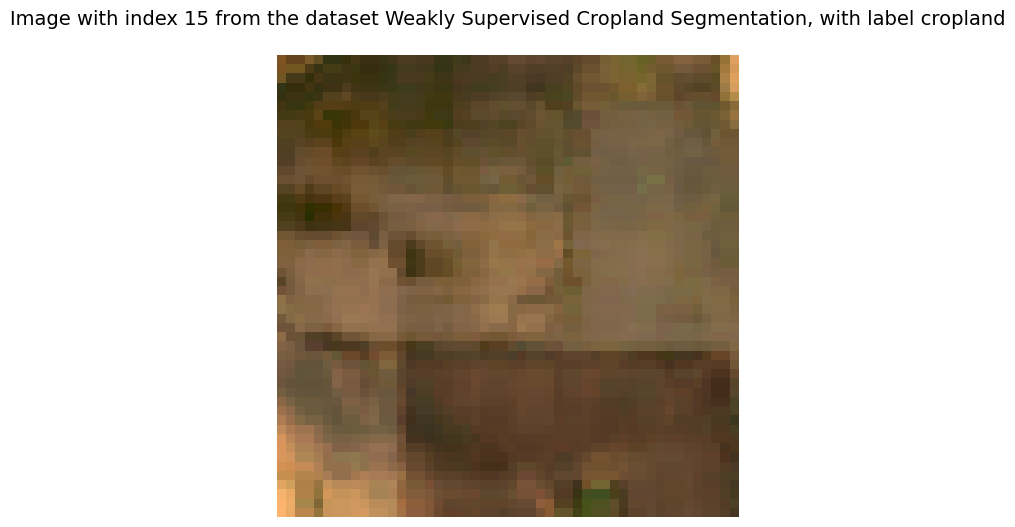

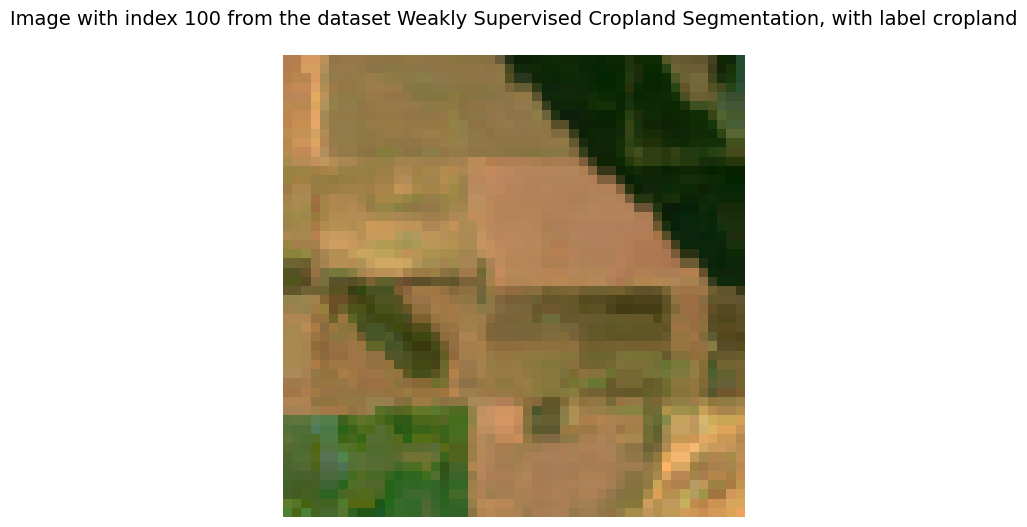

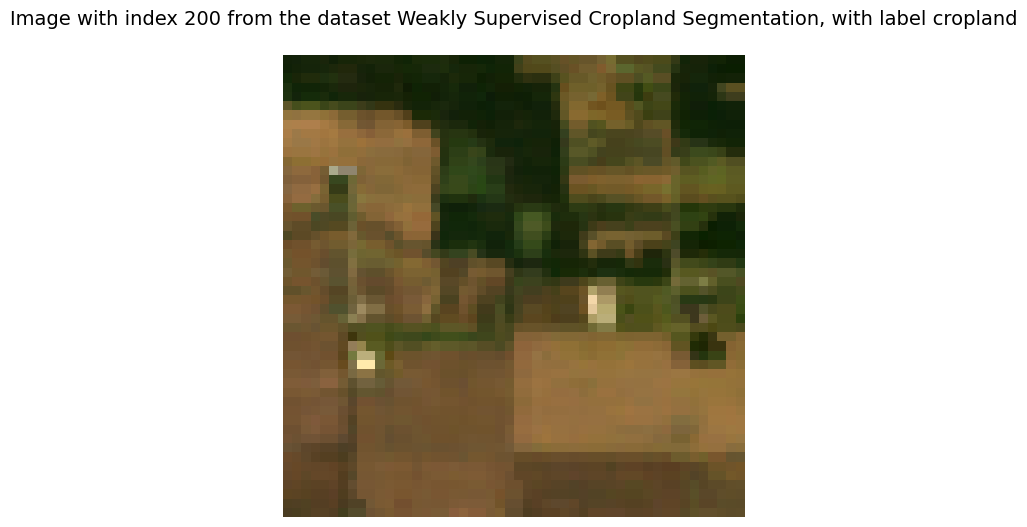

In [37]:
dataset.show_image(15);
dataset.show_image(100);
dataset.show_image(200);

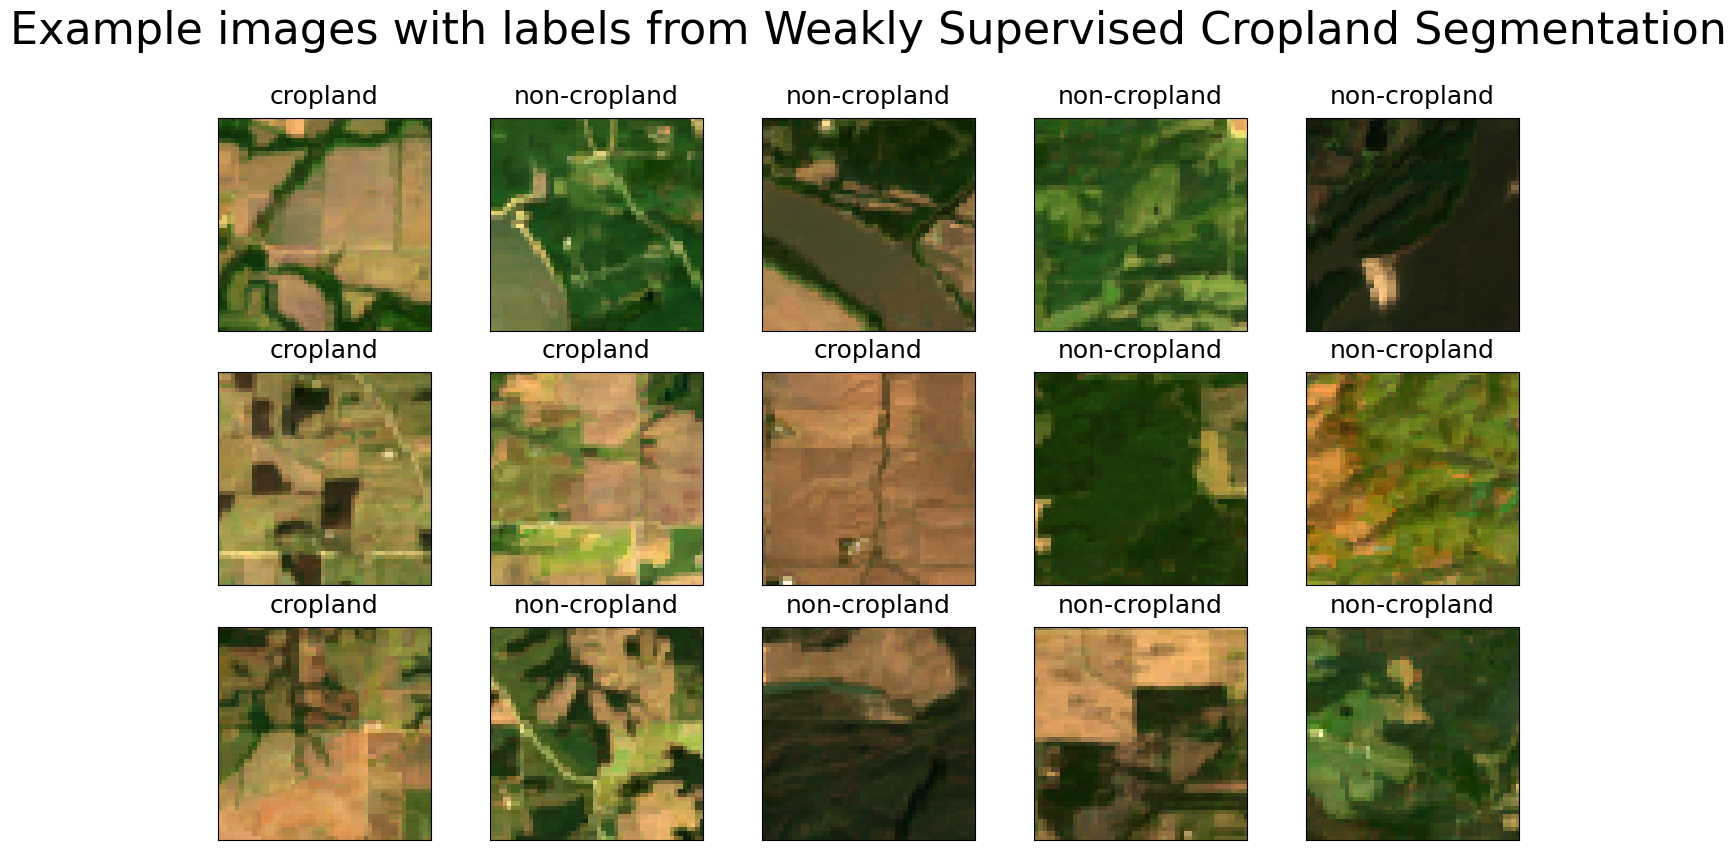

In [44]:
dataset.show_batch(15);

In [45]:
dataset.data_distribution_table()

,Label,Count
0,non-cropland,110059
1,cropland,84117


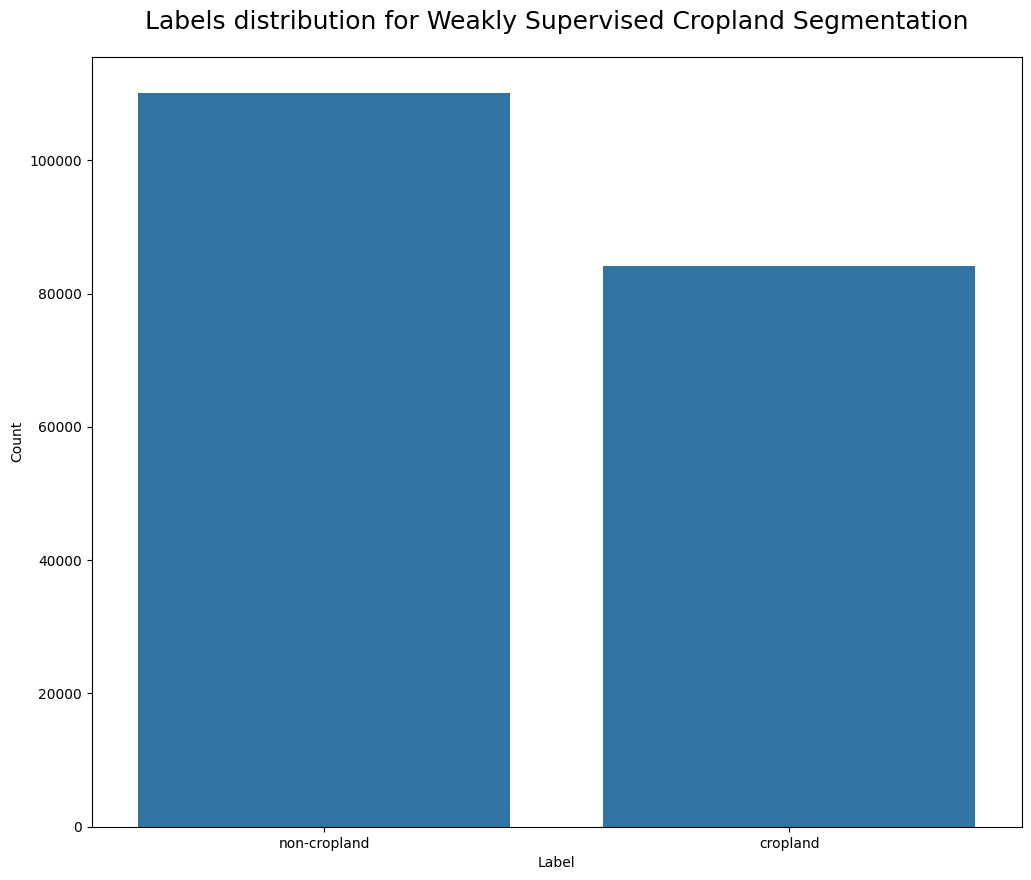

In [20]:
dataset.data_distribution_barchart();

## Load training and validation splits ##

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/wscs_image_classification/weakly_supervised_cropland",
    "mode": "train"
}
train_dataset = WSCSImageClassificationDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/wscs_image_classification/weakly_supervised_cropland",
    "mode": "val",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = WSCSImageClassificationDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(151700, 42476)

## Create the model ##

In [7]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/weak_cropland/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-10-03 06:40:28,785 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-10-03 06:40:28,988 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Start the training ##

In [8]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-10-03 06:40:29,064 INFO Starting training.
training: 100%|██████████| 4741/4741 [19:48<00:00,  3.99it/s]
2025-10-03 07:00:17,142 INFO epoch: 1, time: 1188, loss:  0.14559
testing on train set: 100%|██████████| 4741/4741 [07:09<00:00, 11.05it/s]
2025-10-03 07:07:29,067 INFO Accuracy:0.9235135135135135, Precision Micro:0.9235135135135135, Precision Macro:0.94021803222605, Precision Weighted:0.930506731023519, Precision per Class:[0.89023824 0.99019783], Recall Micro:0.9235135135135135, Recall Macro:0.9063855356073011, Recall Weighted:0.9235135135135134, Recall per Class:[0.9945357  0.81823537], F1_score Micro:0.923513513513513, F1_score Macro:0.917770967765412, F1_score Weighted:0.921993255137784, F1_score per Class:[0.93950122 0.89604071]
testing on validation set: 100%|██████████| 1328/1328 [01:58<00:00, 11.20it/s]
2025-10-03 07:09:27,687 INFO Accuracy:0.9125859308786138, Precision Micro:0.9125859308786138, Precision Macro:0.917645363109799, Precision Weighted:0.9235737561817515, 

0.10086387801213079

## Predictions ##

2025-10-03 12:04:50,247 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/weak_cropland/checkpoint.pth.tar
2025-10-03 12:04:50,513 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/weak_cropland/checkpoint.pth.tar at epoch 11


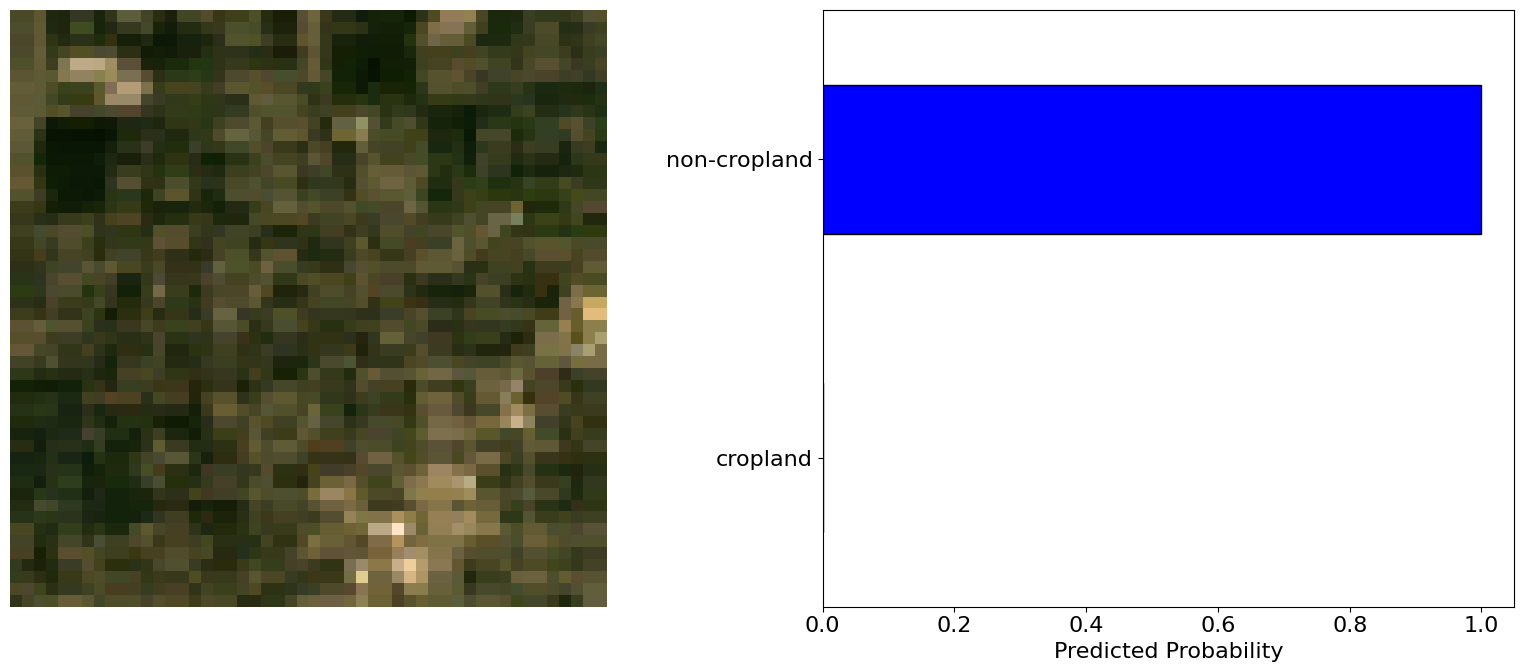

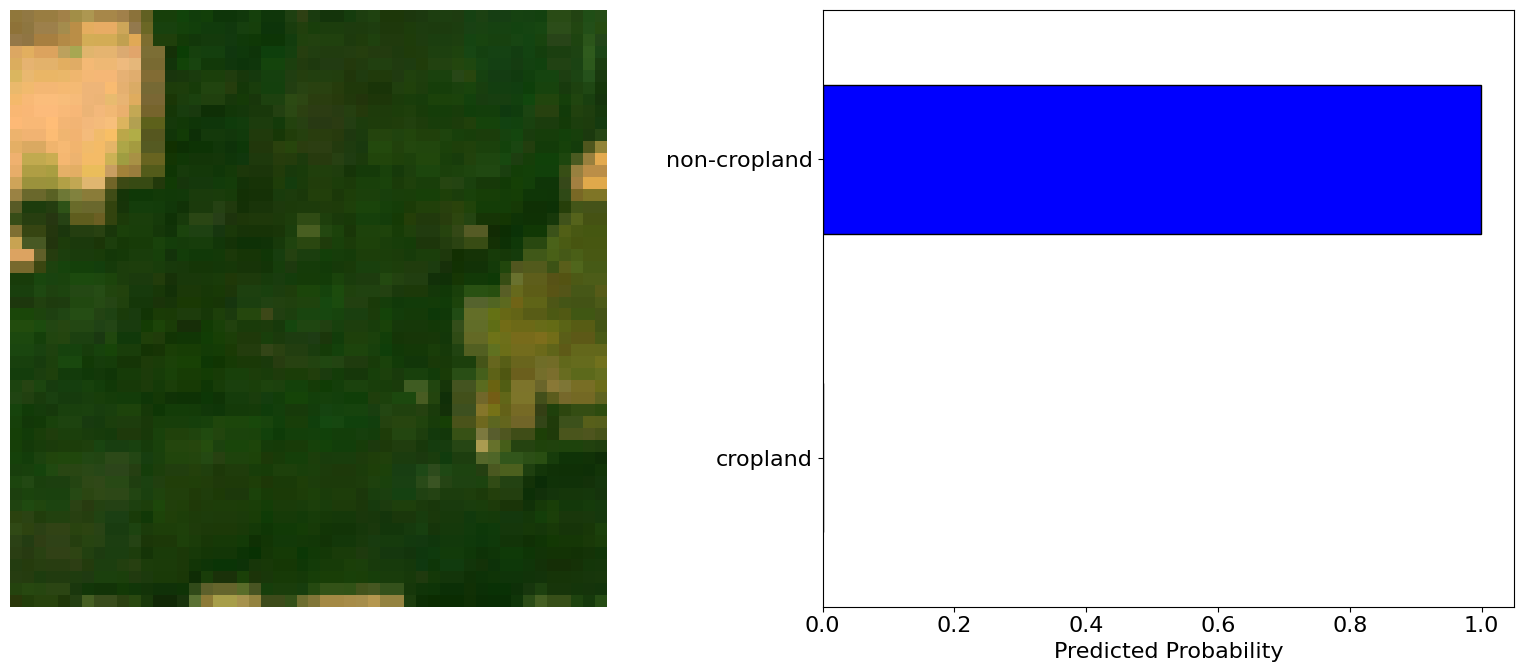

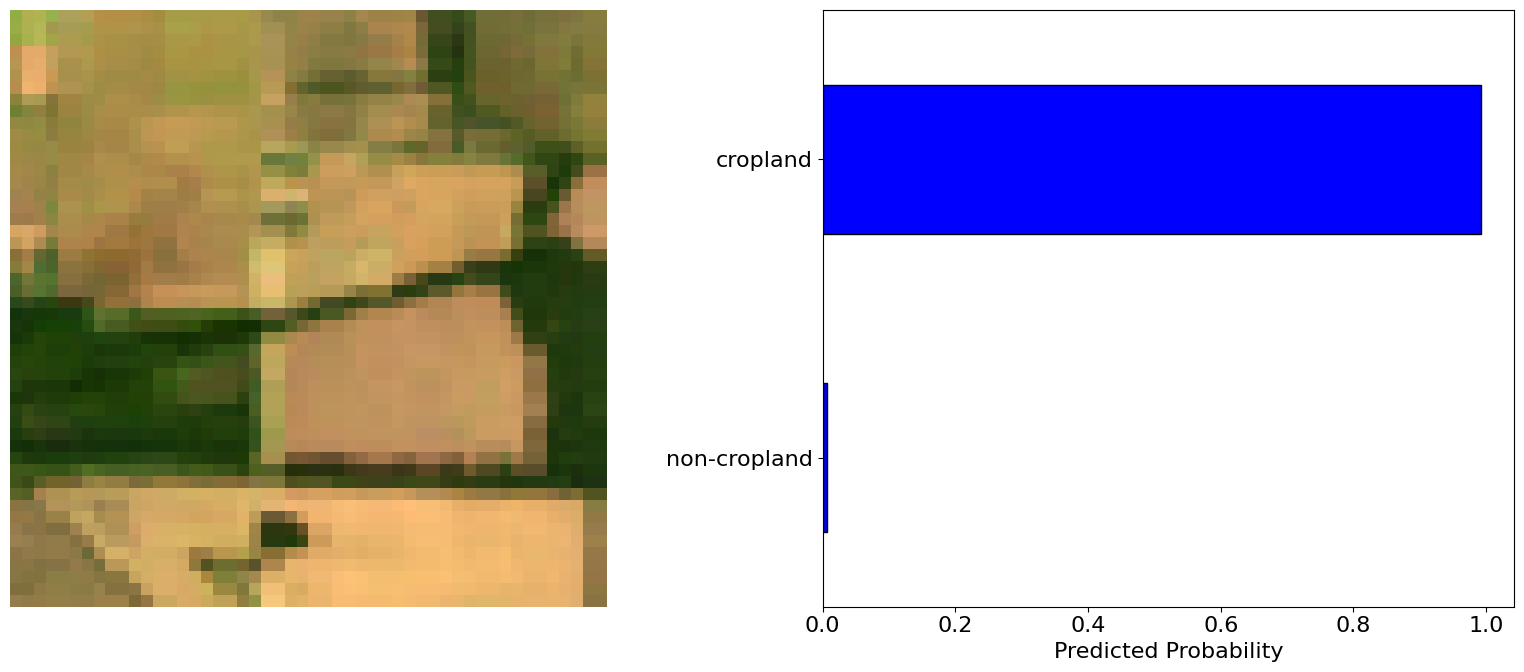

In [ ]:
test_dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/wscs_image_classification/weakly_supervised_cropland",
    "mode": "test"
}
test_dataset = WSCSImageClassificationDataset(test_dataset_config)
labels = ["non-cropland","cropland"]
transform = ResizeCenterCropToTensor()

model_path = "/home/dragik/data/FAIR_EO/experiments/weak_cropland/checkpoint.pth.tar"
model.load_model(model_path)

image = test_dataset[0][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_image(image, labels, transform)